# Actividad 1 – Visualización de datos
## Dataset 1: US Police Shootings (año 2015)

### Introducción

**Objetivo del análisis.** Desde enero de 2015, *The Washington Post* registra cada tiroteo en el que un oficial de policía en servicio causó una muerte. Como analistas, buscamos generar *insights* para un panel de expertos de una organización de derechos humanos que investiga un posible abuso de autoridad con posible carga racial.

**Alcance.** Solo se consideran los registros de **2015**, como indica la actividad. Todos los resultados se calculan con los archivos entregados por el profesor (el dataset fue modificado respecto al original, así que no se usan resultados de Kaggle).

**Información disponible (carpeta `datos/`):**

| Archivo | Contenido |
|---|---|
| `PoliceKillingsUS4.csv` | Una fila por persona fallecida: arma, edad, género, raza, ciudad, estado, indicios de enfermedad mental, fecha (`new_date`), etc. |
| `MedianHouseholdIncome2015.csv` | Ingreso mediano del hogar por **ciudad** (2015). |
| `ShareRaceByCity2.csv` | Porcentaje de población por raza en cada **ciudad**. |
| `population2015.csv` | Población total de cada **estado** en 2015. |
| `Races.csv` | Diccionario de los códigos de raza. |
| `PercentagePeopleBelowPovertyLevel.csv`, `PercentOver25CompletedHighSchool.csv` | Pobreza y escolaridad por ciudad (no se requieren para las preguntas). |

## 1. Preparación de datos

### 1.1 Importación de librerías y estilo de las gráficas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Paleta de colores usada en todo el notebook
AZUL = '#1F3A5F'      # azul marino
NARANJA = '#F28C28'   # naranja (para resaltar)
GRIS = '#8C8C8C'      # gris
GRIS_CLARO = '#D9D9D9'

# Estilo general de las gráficas
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['font.size'] = 10

pd.set_option('display.max_columns', 20)

### 1.2 Lectura de los archivos CSV

Los archivos se leen desde la carpeta local `datos/` (debe estar junto a este notebook).

Dos detalles importantes que se detectaron al revisar los archivos:

* En `PoliceKillingsUS4.csv` el texto `NA` tiene significado: en la columna `race` es el código de **Native American** (según `Races.csv`). Por defecto Pandas convierte `NA` en valor vacío, así que se usa `keep_default_na=False` para conservarlo y después se marcan como faltantes solo los `NA` de `age`, `armed` y `flee`.
* Los archivos de ingreso, pobreza y escolaridad tienen caracteres especiales (acentos) que no están en UTF-8, por eso se leen con `encoding='latin-1'`.

In [2]:
RUTA_DATOS = 'datos/'

muertes = pd.read_csv(RUTA_DATOS + 'PoliceKillingsUS4.csv', keep_default_na=False, na_values=[''])
ingresos = pd.read_csv(RUTA_DATOS + 'MedianHouseholdIncome2015.csv', encoding='latin-1')
razas_ciudad = pd.read_csv(RUTA_DATOS + 'ShareRaceByCity2.csv')
poblacion = pd.read_csv(RUTA_DATOS + 'population2015.csv')
codigos_raza = pd.read_csv(RUTA_DATOS + 'Races.csv', keep_default_na=False, encoding='utf-8-sig')

print('Muertes:', muertes.shape)
print('Ingresos:', ingresos.shape)
print('Raza por ciudad:', razas_ciudad.shape)
print('Población:', poblacion.shape)

Muertes: (2535, 15)
Ingresos: (29322, 3)
Raza por ciudad: (29268, 7)
Población: (50, 3)


### 1.3 Revisión de columnas

In [3]:
muertes.head()

,id,name,manner_of_death,armed,age,gender,race,city,state,State_Name,signs_of_mental_illness,threat_level,flee,body_camera,new_date
0,3,Tim Elliot,shot,gun,53,M,A,Shelton,WA,WASHINGTON,True,attack,Not fleeing,False,01/02/2015
1,4,Lewis Lee Lembke,shot,gun,47,M,W,Aloha,OR,OREGON,False,attack,Not fleeing,False,01/02/2015
2,5,John Paul Quintero,shot and Tasered,unarmed,23,M,H,Wichita,KS,KANSAS,False,other,Not fleeing,False,01/03/2015
3,8,Matthew Hoffman,shot,toy weapon,32,M,W,San Francisco,CA,CALIFORNIA,True,attack,Not fleeing,False,01/04/2015
4,9,Michael Rodriguez,shot,nail gun,39,M,H,Evans,CO,COLORADO,False,attack,Not fleeing,False,01/04/2015


In [4]:
muertes.info()

<class 'pandas.DataFrame'>
RangeIndex: 2535 entries, 0 to 2534
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   id                       2535 non-null   int64
 1   name                     2535 non-null   str  
 2   manner_of_death          2535 non-null   str  
 3   armed                    2535 non-null   str  
 4   age                      2535 non-null   str  
 5   gender                   2535 non-null   str  
 6   race                     2535 non-null   str  
 7   city                     2535 non-null   str  
 8   state                    2535 non-null   str  
 9   State_Name               2535 non-null   str  
 10  signs_of_mental_illness  2535 non-null   bool 
 11  threat_level             2535 non-null   str  
 12  flee                     2535 non-null   str  
 13  body_camera              2535 non-null   bool 
 14  new_date                 2535 non-null   str  
dtypes: bool(2), int

In [5]:
# Diccionario de códigos de raza
codigos_raza

,Race ID,Race
0,A,Asian
1,B,Black
2,H,Hispanic
3,N,Not Hispanic
4,NA,Native American
5,O,Unkown
6,W,White


In [6]:
# Valores reales de las columnas que usaremos en las preguntas
print('Género:', muertes['gender'].value_counts().to_dict())
print('Raza:', muertes['race'].value_counts().to_dict())
print('Enfermedad mental:', muertes['signs_of_mental_illness'].value_counts().to_dict())
print('Valores "NA" en age:', (muertes['age'] == 'NA').sum())
print('Valores "NA" en armed:', (muertes['armed'] == 'NA').sum())

Género: {'M': 2428, 'F': 107}
Raza: {'W': 1201, 'B': 618, 'H': 423, 'NA': 195, 'A': 39, 'N': 31, 'O': 28}
Enfermedad mental: {False: 1902, True: 633}
Valores "NA" en age: 77
Valores "NA" en armed: 9


### 1.4 Limpieza básica

* `new_date` se convierte a fecha (formato mes/día/año) para poder filtrar el año.
* `age` se convierte a número; los `NA` quedan como vacíos y se excluyen solo cuando se filtra por edad.
* `armed` y `flee` con valor `NA` se marcan como faltantes.
* Se agrega el nombre de la raza usando `Races.csv`.

In [7]:
# Fecha y año
muertes['fecha'] = pd.to_datetime(muertes['new_date'], format='%m/%d/%Y')
muertes['anio'] = muertes['fecha'].dt.year

# Edad como número (los 'NA' se convierten en vacío)
muertes['age'] = pd.to_numeric(muertes['age'], errors='coerce')

# 'NA' en arma y huida significa dato faltante
muertes['armed'] = muertes['armed'].replace('NA', pd.NA)
muertes['flee'] = muertes['flee'].replace('NA', pd.NA)

# Nombre de la raza
diccionario_raza = dict(zip(codigos_raza['Race ID'], codigos_raza['Race']))
muertes['raza_nombre'] = muertes['race'].map(diccionario_raza)

# Revisar registros repetidos
print('IDs duplicados:', muertes['id'].duplicated().sum())
print('Filas duplicadas:', muertes.duplicated().sum())

IDs duplicados: 0
Filas duplicadas: 0


### 1.5 Filtro del año 2015

In [8]:
muertes_2015 = muertes[muertes['anio'] == 2015].copy()

print('Registros por año en el archivo:')
print(muertes['anio'].value_counts().sort_index())
print()
print('Registros de 2015:', len(muertes_2015))
print('Desde', muertes_2015['fecha'].min().date(), 'hasta', muertes_2015['fecha'].max().date())

Registros por año en el archivo:
anio
2015    991
2016    963
2017    581
Name: count, dtype: int64

Registros de 2015: 991
Desde 2015-01-02 hasta 2015-12-31


In [9]:
# Datos faltantes en 2015
print('Edad faltante:', muertes_2015['age'].isna().sum())
print('Arma faltante:', muertes_2015['armed'].isna().sum())
print('Huida faltante:', muertes_2015['flee'].isna().sum())

Edad faltante: 11
Arma faltante: 1
Huida faltante: 9


**Manejo de faltantes:** en 2015 hay 991 muertes; 11 no tienen edad y 1 no tiene arma registrada (9 no tienen dato de huida). No se eliminan del análisis general: solo quedan fuera de las preguntas donde se necesita ese dato (filtros por edad o conteo de armas). No hay registros duplicados.

## Pregunta 1
### ¿Cuáles son los estados con mayor número de ciudades diferentes donde ocurrieron tiroteos policiales?

Se cuentan **ciudades distintas** por estado con `nunique()`, no el número de muertes. Para evitar contar dos veces la misma ciudad escrita distinto, se normaliza el nombre (minúsculas y sin espacios extra).

In [10]:
muertes_2015['ciudad_normalizada'] = muertes_2015['city'].str.strip().str.lower()

ciudades_por_estado = muertes_2015.groupby('state')['ciudad_normalizada'].nunique()
ciudades_por_estado = ciudades_por_estado.sort_values(ascending=False)

top10_ciudades = ciudades_por_estado.head(10)
top10_ciudades

state
CA    114
TX     62
FL     42
GA     27
OK     26
AZ     23
CO     21
OH     20
LA     19
NC     19
Name: ciudad_normalizada, dtype: int64

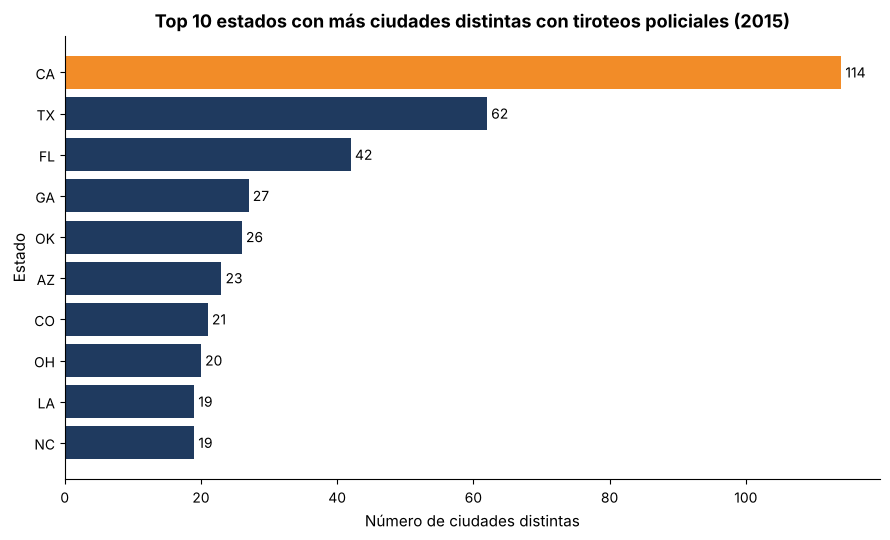

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))

datos_grafica = top10_ciudades.sort_values()
colores = [NARANJA if estado == datos_grafica.index[-1] else AZUL for estado in datos_grafica.index]
barras = ax.barh(datos_grafica.index, datos_grafica.values, color=colores)
ax.bar_label(barras, padding=3)

ax.set_title('Top 10 estados con más ciudades distintas con tiroteos policiales (2015)')
ax.set_xlabel('Número de ciudades distintas')
ax.set_ylabel('Estado')
plt.tight_layout()
plt.show()

**Conclusión:** California (CA) es, por mucho, el estado con más ciudades distintas donde hubo una muerte por tiroteo policial en 2015: **114 ciudades**, casi el doble que Texas (**62**) y casi el triple que Florida (**42**). Después siguen Georgia (27), Oklahoma (26) y Arizona (23). Esto indica que en estos estados los tiroteos no se concentran en una sola ciudad, sino que están dispersos en muchas localidades. Hay que recordar que son estados grandes y con muchas ciudades, por lo que este conteo también refleja su tamaño.

## Pregunta 2
### ¿Cuáles son los niveles de ingreso en los estados con mayor número de muertes de personas que presentaban indicios de enfermedad mental?

Pasos:
1. Filtrar 2015 (ya hecho) y los casos con `signs_of_mental_illness == True`.
2. Contar muertes por estado y elegir los 10 estados con más casos.
3. Cruzar con `MedianHouseholdIncome2015.csv` por **estado y ciudad**.
4. Promediar el ingreso mediano de las ciudades donde ocurrieron los casos.

In [12]:
# Paso 1: casos con indicios de enfermedad mental
enfermedad_mental = muertes_2015[muertes_2015['signs_of_mental_illness'] == True]
print('Muertes con indicios de enfermedad mental en 2015:', len(enfermedad_mental))

# Paso 2: top 10 estados
muertes_mental_estado = enfermedad_mental['state'].value_counts()
top10_mental = muertes_mental_estado.head(10)
top10_mental

Muertes con indicios de enfermedad mental en 2015: 254


state
CA    50
TX    24
AZ    12
FL    11
WA     9
AL     8
LA     8
GA     7
OR     7
OK     7
Name: count, dtype: int64

**Preparación de la tabla de ingresos.**

* La columna `Median Income` es texto: tiene celdas vacías y el valor `250,000+`. El valor `250,000+` se toma como 250,000 (es el límite superior reportado) y las celdas vacías se excluyen.
* En la tabla de ingresos las ciudades tienen un sufijo (`Los Angeles city`, `Abanda CDP`, `Akron town`...), mientras que en la tabla de muertes solo aparece `Los Angeles`. Por eso se quita el sufijo y se pasa a minúsculas.
* Al quitar el sufijo, algunos nombres se repiten en un mismo estado (por ejemplo `Salem city` y `Salem CDP`). Para no duplicar casos en el cruce, se deja **una sola fila por estado y ciudad** promediando su ingreso.

In [13]:
print('Celdas vacías en Median Income:', ingresos['Median Income'].isna().sum())
print('Celdas con "250,000+":', (ingresos['Median Income'] == '250,000+').sum())

ingresos['ingreso_mediano'] = ingresos['Median Income'].replace('250,000+', '250000')
ingresos['ingreso_mediano'] = pd.to_numeric(ingresos['ingreso_mediano'], errors='coerce')

# Normalizar nombre de ciudad: minúsculas, sin '(balance)' y sin el sufijo final
ingresos['ciudad_normalizada'] = ingresos['City'].str.lower()
ingresos['ciudad_normalizada'] = ingresos['ciudad_normalizada'].str.replace(' (balance)', '', regex=False)
ingresos['ciudad_normalizada'] = ingresos['ciudad_normalizada'].str.replace(
    r' (city|cdp|town|village|borough|municipality)$', '', regex=True)
ingresos['ciudad_normalizada'] = ingresos['ciudad_normalizada'].str.strip()

ingresos[['Geographic Area', 'City', 'ciudad_normalizada', 'ingreso_mediano']].head()

Celdas vacías en Median Income: 1913
Celdas con "250,000+": 24


,Geographic Area,City,ciudad_normalizada,ingreso_mediano
0,AL,Abanda CDP,abanda,11207.0
1,AL,Abbeville city,abbeville,25615.0
2,AL,Adamsville city,adamsville,42575.0
3,AL,Addison town,addison,37083.0
4,AL,Akron town,akron,21667.0


In [14]:
# Una fila por estado + ciudad (se eliminan vacíos y se promedian nombres repetidos)
ingresos_ciudad = ingresos.dropna(subset=['ingreso_mediano'])
ingresos_ciudad = ingresos_ciudad.groupby(['Geographic Area', 'ciudad_normalizada'], as_index=False)['ingreso_mediano'].mean()
ingresos_ciudad = ingresos_ciudad.rename(columns={'Geographic Area': 'state'})

print('Ciudades con ingreso disponible:', len(ingresos_ciudad))
print('¿Quedan duplicados?', ingresos_ciudad.duplicated(['state', 'ciudad_normalizada']).sum())

Ciudades con ingreso disponible: 27326
¿Quedan duplicados? 0


In [15]:
# Paso 3: cruce por estado y ciudad (solo casos de los 10 estados seleccionados)
casos_top10 = enfermedad_mental[enfermedad_mental['state'].isin(top10_mental.index)]

cruce = casos_top10.merge(ingresos_ciudad, on=['state', 'ciudad_normalizada'], how='left')

print('Casos en los 10 estados:', len(casos_top10))
print('Filas después del merge:', len(cruce), '(deben ser iguales: no se duplicaron casos)')
print('Casos con ingreso encontrado:', cruce['ingreso_mediano'].notna().sum())
print('Casos sin ingreso:', cruce['ingreso_mediano'].isna().sum())
print('Porcentaje cruzado: {:.1f}%'.format(cruce['ingreso_mediano'].notna().mean() * 100))

Casos en los 10 estados: 143
Filas después del merge: 143 (deben ser iguales: no se duplicaron casos)
Casos con ingreso encontrado: 126
Casos sin ingreso: 17
Porcentaje cruzado: 88.1%


In [16]:
# Ciudades que no se pudieron cruzar
cruce[cruce['ingreso_mediano'].isna()][['state', 'city']]

,state,city
17,OR,Colton
31,AL,Lawrence County
37,CA,Wilmington
49,CA,Sylmar
67,GA,Rockville
71,TX,Ellis County
76,TX,Bexar County
81,GA,Augusta
94,CA,San Diego County
97,WA,Hunters


In [17]:
# Paso 4: promedio del ingreso mediano de las CIUDADES donde hubo casos
# (cada ciudad cuenta una vez, aunque tenga varios casos)
ciudades_con_casos = cruce.dropna(subset=['ingreso_mediano']).drop_duplicates(['state', 'ciudad_normalizada'])

resumen_ingreso = ciudades_con_casos.groupby('state').agg(
    ingreso_promedio=('ingreso_mediano', 'mean'),
    ciudades_con_ingreso=('ciudad_normalizada', 'count'))

resumen_ingreso['muertes_mental'] = top10_mental
resumen_ingreso = resumen_ingreso.sort_values('muertes_mental', ascending=False)
resumen_ingreso['ingreso_promedio'] = resumen_ingreso['ingreso_promedio'].round(0)
resumen_ingreso

,ingreso_promedio,ciudades_con_ingreso,muertes_mental
state,,,
CA,64445.0,32,50
TX,48834.0,17,24
AZ,47311.0,9,12
FL,47300.0,9,11
WA,53094.0,8,9
AL,45766.0,6,8
LA,41044.0,6,8
GA,50676.0,4,7
OR,51450.0,4,7


In [18]:
# Referencia: promedio de todas las ciudades con ingreso en el archivo
promedio_todas_ciudades = ingresos_ciudad['ingreso_mediano'].mean()
print('Promedio del ingreso mediano de todas las ciudades del archivo: ${:,.0f}'.format(promedio_todas_ciudades))

Promedio del ingreso mediano de todas las ciudades del archivo: $51,334


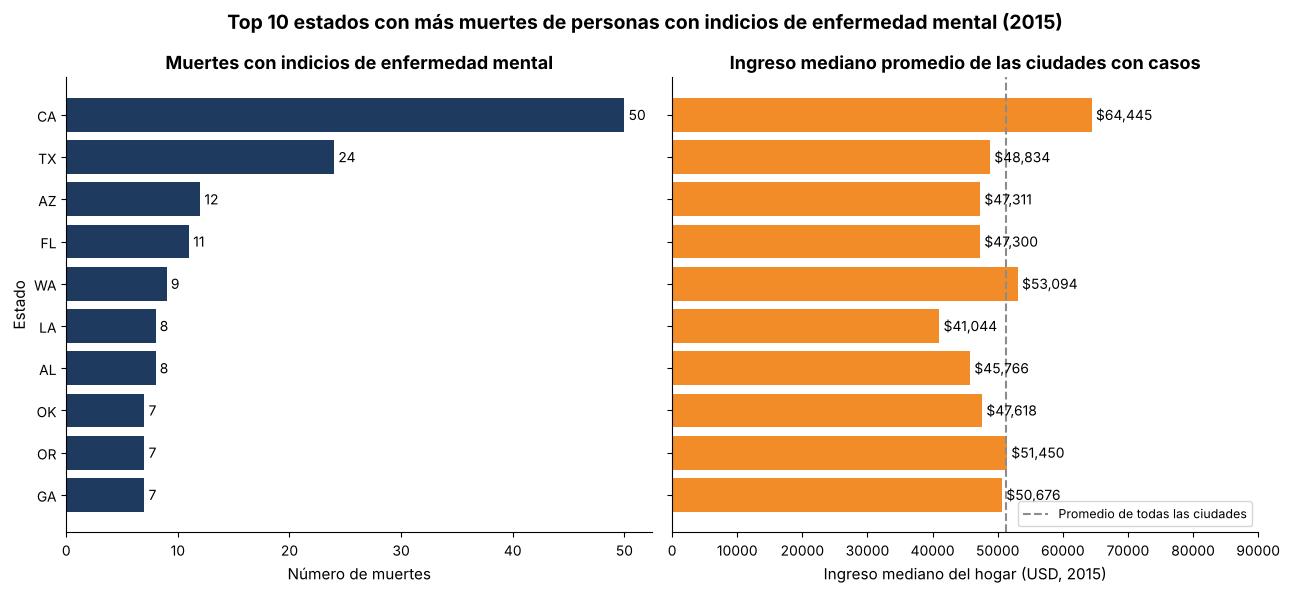

In [19]:
datos_grafica = resumen_ingreso.sort_values('muertes_mental')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6), sharey=True)

# Panel izquierdo: número de muertes
barras1 = ax1.barh(datos_grafica.index, datos_grafica['muertes_mental'], color=AZUL)
ax1.bar_label(barras1, padding=3)
ax1.set_title('Muertes con indicios de enfermedad mental')
ax1.set_xlabel('Número de muertes')
ax1.set_ylabel('Estado')

# Panel derecho: ingreso promedio de las ciudades
barras2 = ax2.barh(datos_grafica.index, datos_grafica['ingreso_promedio'], color=NARANJA)
ax2.bar_label(barras2, labels=['${:,.0f}'.format(v) for v in datos_grafica['ingreso_promedio']], padding=3)
ax2.axvline(promedio_todas_ciudades, color=GRIS, linestyle='--', label='Promedio de todas las ciudades')
ax2.set_title('Ingreso mediano promedio de las ciudades con casos')
ax2.set_xlabel('Ingreso mediano del hogar (USD, 2015)')
ax2.set_xlim(0, 90000)
ax2.legend(loc='lower right', fontsize=9)

fig.suptitle('Top 10 estados con más muertes de personas con indicios de enfermedad mental (2015)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Conclusión:** De las 254 muertes de 2015 con indicios de enfermedad mental, California concentra **50**, seguida de Texas (**24**), Arizona (12) y Florida (11). En las ciudades donde ocurrieron estos casos, el ingreso mediano promedio va de unos **$41,044** (Luisiana) a **$64,445** (California); solo California, Washington ($53,094) y Oregón ($51,450) quedan por encima del promedio de todas las ciudades del archivo (**$51,334**); los otros 7 estados están por debajo, entre $41,000 y $51,000. No se observa que los estados con más muertes sean los de menor ingreso: California, el de más casos, tiene el ingreso más alto. Es decir, el nivel de ingreso no parece explicar por sí solo estos casos.

**Limitaciones:** el ingreso es de **ciudades**, no un ingreso estatal oficial; es el promedio simple de las ciudades donde hubo casos. Se cruzaron **126 de 143 casos (88.1 %)**; no cruzaron los que están registrados como condados (*Bexar County*), barrios (*Sylmar*, *Wilmington*) o nombres que no aparecen igual en la tabla de ingresos. Georgia solo tiene 4 ciudades con ingreso, por lo que su promedio es menos confiable.

## Pregunta 3
### ¿Cuáles fueron las armas más comunes registradas entre las personas fallecidas?

Se cuentan los valores de la columna `armed` en 2015. Los registros sin arma registrada (`NA`) no se incluyen. Valores como `unarmed` (desarmado) y `undetermined` (no determinado) sí se muestran porque son categorías registradas.

In [20]:
armas = muertes_2015['armed'].value_counts()   # value_counts ignora los faltantes
print('Registros con arma conocida:', armas.sum())
print('Tipos de arma distintos:', len(armas))

top10_armas = armas.head(10)
porcentaje_armas = (top10_armas / armas.sum() * 100).round(1)
pd.DataFrame({'muertes': top10_armas, 'porcentaje': porcentaje_armas})

Registros con arma conocida: 990
Tipos de arma distintos: 41


,muertes,porcentaje
armed,,
gun,560,56.6
knife,137,13.8
unarmed,94,9.5
vehicle,55,5.6
toy weapon,43,4.3
undetermined,27,2.7
machete,9,0.9
box cutter,7,0.7
sword,6,0.6


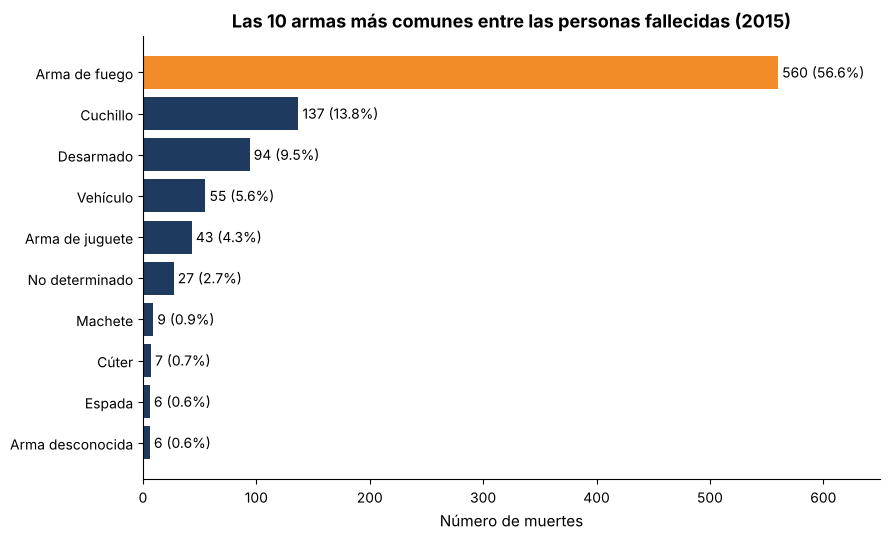

In [21]:
# Nombres en español para la gráfica
nombres_armas = {
    'gun': 'Arma de fuego', 'knife': 'Cuchillo', 'unarmed': 'Desarmado', 'vehicle': 'Vehículo',
    'toy weapon': 'Arma de juguete', 'undetermined': 'No determinado', 'machete': 'Machete',
    'box cutter': 'Cúter', 'sword': 'Espada', 'unknown weapon': 'Arma desconocida'}

datos_grafica = top10_armas.sort_values()
etiquetas = [nombres_armas.get(arma, arma) for arma in datos_grafica.index]
colores = [NARANJA if arma == 'gun' else AZUL for arma in datos_grafica.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
barras = ax.barh(etiquetas, datos_grafica.values, color=colores)
porcentajes = datos_grafica / armas.sum() * 100
ax.bar_label(barras, labels=['{} ({:.1f}%)'.format(n, p) for n, p in zip(datos_grafica.values, porcentajes)], padding=3)

ax.set_title('Las 10 armas más comunes entre las personas fallecidas (2015)')
ax.set_xlabel('Número de muertes')
ax.set_xlim(0, 650)
plt.tight_layout()
plt.show()

**Conclusión:** El arma de fuego (`gun`) es por mucho la más común: **560 de 990 casos con arma registrada (56.6 %)**. Le siguen el cuchillo (**137**, 13.8 %) y, en tercer lugar, personas **desarmadas** (**94**, 9.5 %). También destacan los vehículos (55) y las armas de juguete (43). Que casi 1 de cada 10 personas fallecidas estuviera desarmada es un dato relevante para el panel de derechos humanos, porque son casos donde el uso de fuerza letal es más cuestionable.

## Pregunta 4
### ¿En qué estados ocurrieron tiroteos donde las víctimas tenían armas de juguete?

Se filtra `armed == 'toy weapon'` y se cuentan los casos por estado.

In [22]:
juguete = muertes_2015[muertes_2015['armed'] == 'toy weapon']
juguete_por_estado = juguete['state'].value_counts()

print('Muertes con arma de juguete en 2015:', len(juguete))
print('Número de estados:', len(juguete_por_estado))
juguete_por_estado

Muertes con arma de juguete en 2015: 43
Número de estados: 24


state
CA    10
TX     4
PA     3
TN     3
MA     2
IN     2
NV     2
AL     1
UT     1
AZ     1
MO     1
WA     1
OK     1
OR     1
WY     1
LA     1
NJ     1
NC     1
OH     1
KY     1
CO     1
MN     1
NM     1
VA     1
Name: count, dtype: int64

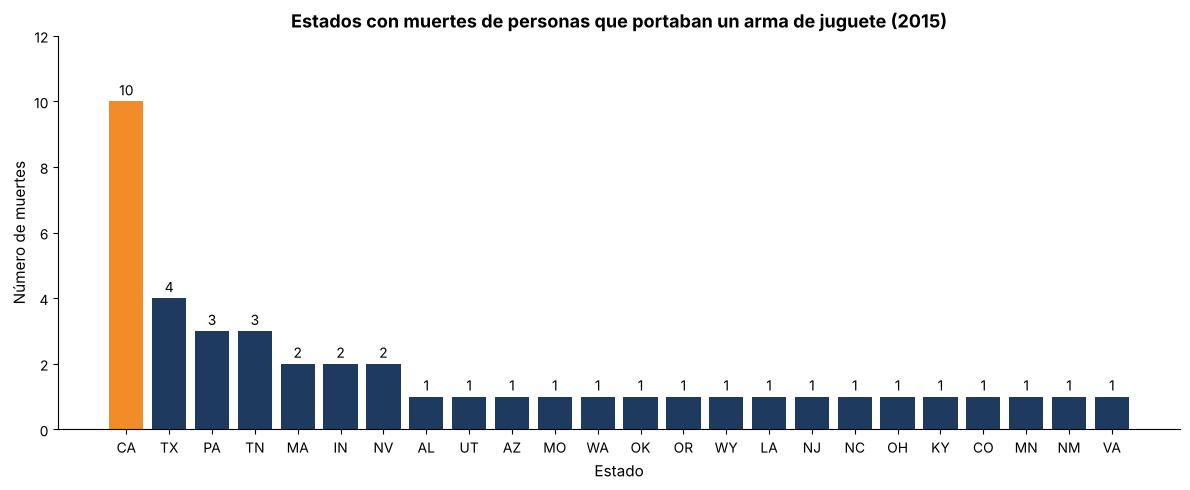

In [23]:
fig, ax = plt.subplots(figsize=(12, 5))

colores = [NARANJA if n == juguete_por_estado.max() else AZUL for n in juguete_por_estado.values]
barras = ax.bar(juguete_por_estado.index, juguete_por_estado.values, color=colores)
ax.bar_label(barras, padding=2)

ax.set_title('Estados con muertes de personas que portaban un arma de juguete (2015)')
ax.set_xlabel('Estado')
ax.set_ylabel('Número de muertes')
ax.set_ylim(0, 12)
plt.tight_layout()
plt.show()

**Conclusión:** En 2015 hubo **43 muertes** de personas que portaban un arma de juguete, repartidas en **24 estados**. California tiene el mayor número (**10**), seguida de Texas (**4**), Pensilvania y Tennessee (**3** cada uno); en la mayoría de los demás estados solo hubo 1 caso. Aunque el número es pequeño, es un tipo de caso importante porque la persona no tenía un arma real, lo que plantea preguntas sobre la evaluación de la amenaza por parte de los oficiales.

## Pregunta 5
### Para hombres blancos de entre 25 y 40 años, ¿qué estados registraron más muertes por tiroteos policiales?

Filtro: `gender == 'M'`, `race == 'W'` y `age` entre 25 y 40 **incluyendo ambos extremos** (`between(25, 40)`). Los registros sin edad quedan fuera.

In [24]:
hombres_blancos = muertes_2015[(muertes_2015['gender'] == 'M') &
                               (muertes_2015['race'] == 'W') &
                               (muertes_2015['age'].between(25, 40))]

print('Hombres blancos de 25 a 40 años fallecidos en 2015:', len(hombres_blancos))
print('Edad mínima y máxima del filtro:', hombres_blancos['age'].min(), '-', hombres_blancos['age'].max())

hombres_blancos_estado = hombres_blancos['state'].value_counts()
hombres_blancos_estado.head(10)

Hombres blancos de 25 a 40 años fallecidos en 2015: 192
Edad mínima y máxima del filtro: 25.0 - 40.0


state
CA    27
TX    14
AZ    10
FL    10
GA     8
OK     8
WA     6
MO     5
TN     5
OR     5
Name: count, dtype: int64

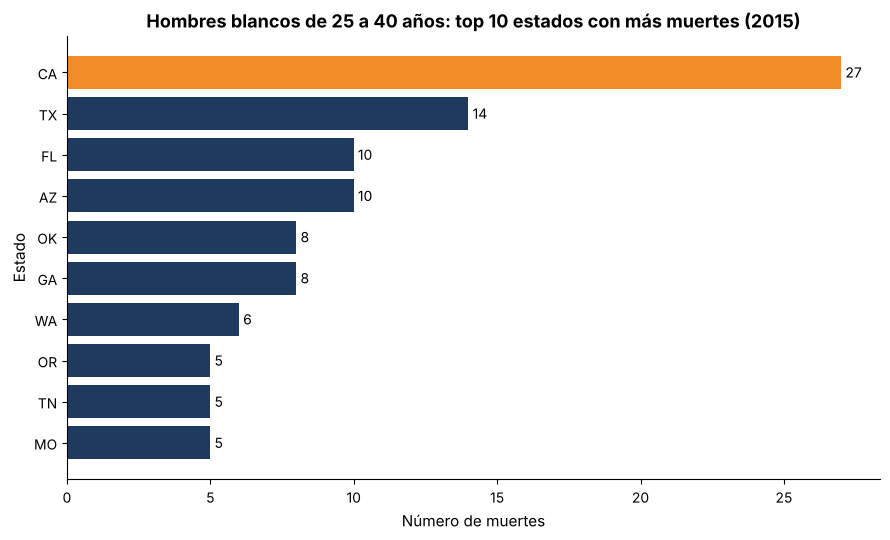

In [25]:
top10_hb = hombres_blancos_estado.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
colores = [NARANJA if estado == top10_hb.index[-1] else AZUL for estado in top10_hb.index]
barras = ax.barh(top10_hb.index, top10_hb.values, color=colores)
ax.bar_label(barras, padding=3)

ax.set_title('Hombres blancos de 25 a 40 años: top 10 estados con más muertes (2015)')
ax.set_xlabel('Número de muertes')
ax.set_ylabel('Estado')
plt.tight_layout()
plt.show()

**Conclusión:** Se registraron **192 muertes** de hombres blancos de 25 a 40 años en 2015. California encabeza la lista con **27**, seguida de Texas (**14**), Arizona y Florida (**10** cada uno) y Georgia y Oklahoma (**8** cada uno). Estos son los estados donde **más casos** hubo para este perfil. Sin embargo, un conteo mayor no significa automáticamente una mayor probabilidad: California y Texas son los estados más poblados. Por eso en el análisis complementario se calculan tasas por millón de habitantes.

## Pregunta 6
### Para mujeres negras de entre 25 y 40 años, ¿qué estados registraron más muertes por tiroteos policiales?

Filtro: `gender == 'F'`, `race == 'B'` y `age` entre 25 y 40 (incluyendo extremos).

In [26]:
mujeres_negras = muertes_2015[(muertes_2015['gender'] == 'F') &
                              (muertes_2015['race'] == 'B') &
                              (muertes_2015['age'].between(25, 40))]

print('Mujeres negras de 25 a 40 años fallecidas en 2015:', len(mujeres_negras))
mujeres_negras_estado = mujeres_negras['state'].value_counts()
mujeres_negras_estado

Mujeres negras de 25 a 40 años fallecidas en 2015: 6


state
CA    3
MD    1
GA    1
VA    1
Name: count, dtype: int64

In [27]:
# Detalle de los casos (son pocos, se pueden mostrar todos)
mujeres_negras[['name', 'age', 'city', 'state', 'armed', 'fecha']]

,name,age,city,state,armed,fecha
80,Yuvette Henderson,38.0,Emeryville,CA,gun,2015-02-03
235,Megan Hockaday,26.0,Oxnard,CA,knife,2015-03-27
244,Mya Hall,27.0,Fort Meade,MD,vehicle,2015-03-31
324,Alexia Christian,25.0,Atlanta,GA,gun,2015-04-29
605,Redel Jones,30.0,Los Angeles,CA,knife,2015-08-12
676,India Kager,28.0,Virginia Beach,VA,unarmed,2015-09-05


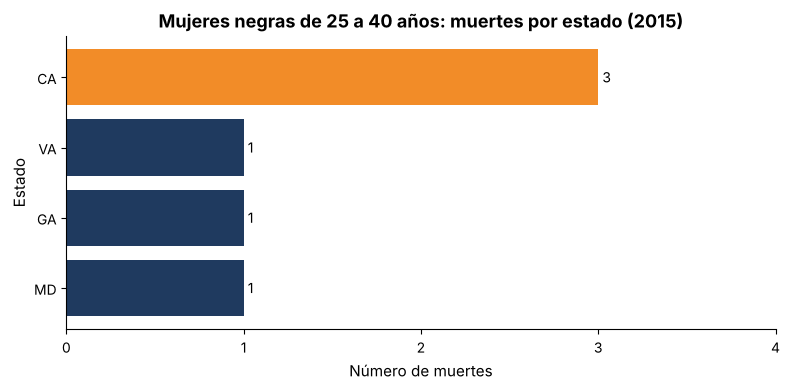

In [28]:
datos_grafica = mujeres_negras_estado.sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
colores = [NARANJA if n == datos_grafica.max() else AZUL for n in datos_grafica.values]
barras = ax.barh(datos_grafica.index, datos_grafica.values, color=colores)
ax.bar_label(barras, padding=3)

ax.set_title('Mujeres negras de 25 a 40 años: muertes por estado (2015)')
ax.set_xlabel('Número de muertes')
ax.set_ylabel('Estado')
ax.set_xticks(range(0, 5))
plt.tight_layout()
plt.show()

**Conclusión:** En 2015 solo hubo **6 muertes** de mujeres negras de 25 a 40 años: **3 en California** y 1 en cada uno de Georgia, Maryland y Virginia. California vuelve a aparecer en primer lugar, pero con un número tan pequeño de casos no se pueden sacar conclusiones fuertes sobre qué estado es "más probable"; una sola muerte más o menos cambiaría el orden. Lo que sí se observa es que, en general, las mujeres representan muy pocos casos (42 de 991 en 2015).

## Análisis complementario

### A. Muertes por estado vs. tasa por población

El número de muertes depende mucho del tamaño del estado. Para comparar de forma justa se calcula la **tasa de muertes por cada millón de habitantes**:

$$\text{tasa} = \frac{\text{muertes 2015}}{\text{población 2015}} \times 1{,}000{,}000$$

Nota: `population2015.csv` no incluye a Washington D. C. (DC), por lo que DC (4 muertes en 2015) queda fuera de las tasas. Rhode Island (RI) no tuvo muertes en 2015 y se incluye con 0. No se agregó información externa.

In [29]:
# Población como número (viene con comas)
poblacion['poblacion_2015'] = poblacion['2015 population'].str.replace(',', '').astype(int)
poblacion = poblacion.rename(columns={'ID State': 'state'})

muertes_estado = muertes_2015['state'].value_counts().rename_axis('state').reset_index(name='muertes')

# Estados de muertes que no están en la tabla de población
print('Estados sin población:', muertes_estado[~muertes_estado['state'].isin(poblacion['state'])]['state'].tolist())

# Partimos de la tabla de población para incluir también estados sin muertes en 2015
tasas = poblacion[['state', 'poblacion_2015']].merge(muertes_estado, on='state', how='left')
print('Estados sin muertes en 2015:', tasas[tasas['muertes'].isna()]['state'].tolist())
tasas['muertes'] = tasas['muertes'].fillna(0).astype(int)
tasas['muertes_por_millon'] = (tasas['muertes'] / tasas['poblacion_2015'] * 1_000_000).round(2)

tasa_nacional = tasas['muertes'].sum() / tasas['poblacion_2015'].sum() * 1_000_000
print('Tasa nacional (50 estados): {:.2f} muertes por millón'.format(tasa_nacional))

Estados sin población: ['DC']
Estados sin muertes en 2015: ['RI']
Tasa nacional (50 estados): 3.08 muertes por millón


In [30]:
top10_conteo = tasas.sort_values('muertes', ascending=False).head(10)
top10_tasa = tasas.sort_values('muertes_por_millon', ascending=False).head(10)

print('Posición de California por número de muertes:',
      tasas.sort_values('muertes', ascending=False)['state'].tolist().index('CA') + 1)
print('Posición de California por tasa:',
      tasas.sort_values('muertes_por_millon', ascending=False)['state'].tolist().index('CA') + 1)
top10_tasa

Posición de California por número de muertes: 1
Posición de California por tasa: 10


,state,poblacion_2015,muertes,muertes_por_millon
49,WY,586107,6,10.24
30,NM,2085109,20,9.59
35,OK,3911338,32,8.18
27,NV,2890845,19,6.57
2,AZ,6828065,42,6.15
17,LA,4649676,27,5.81
1,AK,738432,4,5.42
47,WV,1844128,10,5.42
5,CO,5456574,29,5.31
4,CA,39144818,189,4.83


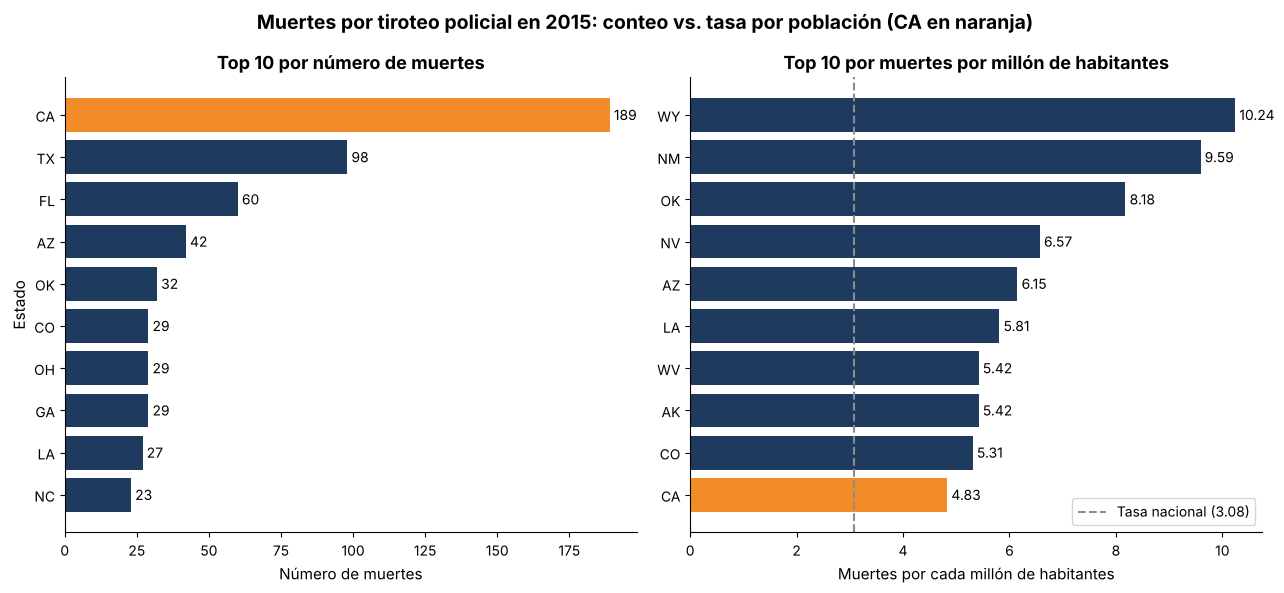

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

# Izquierda: número de muertes
datos1 = top10_conteo.sort_values('muertes')
colores1 = [NARANJA if s == 'CA' else AZUL for s in datos1['state']]
barras1 = ax1.barh(datos1['state'], datos1['muertes'], color=colores1)
ax1.bar_label(barras1, padding=3)
ax1.set_title('Top 10 por número de muertes')
ax1.set_xlabel('Número de muertes')
ax1.set_ylabel('Estado')

# Derecha: muertes por millón de habitantes
datos2 = top10_tasa.sort_values('muertes_por_millon')
colores2 = [NARANJA if s == 'CA' else AZUL for s in datos2['state']]
barras2 = ax2.barh(datos2['state'], datos2['muertes_por_millon'], color=colores2)
ax2.bar_label(barras2, fmt='%.2f', padding=3)
ax2.axvline(tasa_nacional, color=GRIS, linestyle='--', label='Tasa nacional ({:.2f})'.format(tasa_nacional))
ax2.set_title('Top 10 por muertes por millón de habitantes')
ax2.set_xlabel('Muertes por cada millón de habitantes')
ax2.legend(loc='lower right')

fig.suptitle('Muertes por tiroteo policial en 2015: conteo vs. tasa por población (CA en naranja)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Resultado:** California tiene el mayor **número** de muertes (**189**), pero al dividir entre su población (39.1 millones) su tasa es de **4.83 muertes por millón**, lo que la coloca en el **lugar 10** de 50 estados. Los estados con mayor tasa son Wyoming (**10.24**), Nuevo México (**9.59**) y Oklahoma (**8.18**). La tasa nacional es de **3.08**: California está por encima del promedio, pero no es el estado con mayor riesgo relativo. (Wyoming tiene solo 6 muertes, así que su tasa es sensible a pocos casos.)

### B. Comparación racial con los datos demográficos disponibles

Los datos de población por raza (`ShareRaceByCity2.csv`) son **porcentajes por ciudad** y no incluyen el tamaño de cada ciudad. Para obtener una **estimación aproximada** de la población por raza:

1. Se promedia el porcentaje de cada raza en las ciudades de cada estado.
2. Se multiplica ese porcentaje por la población del estado (`population2015.csv`).
3. Se suman todos los estados.

Es una aproximación: el promedio simple da el mismo peso a un pueblo pequeño que a una ciudad grande. Además, *hispano* en el censo puede ser de cualquier raza, por lo que los porcentajes no suman exactamente 100 %. Las 20 ciudades sin datos de raza se excluyen.

In [32]:
print('Ciudades sin datos de raza:', razas_ciudad['share_white'].isna().sum())

columnas_raza = ['share_white', 'share_black', 'share_hispanic', 'share_asian', 'share_native_american']
raza_estado = razas_ciudad.groupby('Geographic area')[columnas_raza].mean()
raza_estado.index.name = 'state'

# Población estimada por raza en cada estado
raza_estado = raza_estado.merge(poblacion[['state', 'poblacion_2015']], left_index=True, right_on='state')
for col in columnas_raza:
    raza_estado['pob_' + col] = raza_estado[col] / 100 * raza_estado['poblacion_2015']

poblacion_estimada = raza_estado[['pob_' + col for col in columnas_raza]].sum()
poblacion_estimada.index = ['W', 'B', 'H', 'A', 'NA']
poblacion_estimada.round(0)

Ciudades sin datos de raza: 20


W     260744539.0
B      24742061.0
H      40437400.0
A       6748970.0
NA      6482850.0
dtype: float64

In [33]:
# Víctimas por raza en 2015 (solo 50 estados, para que coincida con la población)
victimas_50 = muertes_2015[muertes_2015['state'] != 'DC']
victimas_raza = victimas_50['race'].value_counts()
print('Víctimas por raza (todas las categorías):')
print(victimas_raza)

comparacion = pd.DataFrame({'victimas': victimas_raza[['W', 'B', 'H', 'A', 'NA']],
                            'poblacion_estimada': poblacion_estimada})
comparacion['pct_victimas'] = (comparacion['victimas'] / victimas_raza.sum() * 100).round(1)
comparacion['pct_poblacion'] = (comparacion['poblacion_estimada'] / poblacion['poblacion_2015'].sum() * 100).round(1)
comparacion['muertes_por_millon'] = (comparacion['victimas'] / comparacion['poblacion_estimada'] * 1_000_000).round(2)
comparacion['nombre'] = comparacion.index.map(diccionario_raza)
comparacion

Víctimas por raza (todas las categorías):
race
W     495
B     254
H     172
NA     28
O      15
A      14
N       9
Name: count, dtype: int64


,victimas,poblacion_estimada,pct_victimas,pct_poblacion,muertes_por_millon,nombre
W,495,2.607445e+08,50.2,81.3,1.90,White
B,254,2.474206e+07,25.7,7.7,10.27,Black
H,172,4.043740e+07,17.4,12.6,4.25,Hispanic
A,14,6.748970e+06,1.4,2.1,2.07,Asian
NA,28,6.482850e+06,2.8,2.0,4.32,Native American


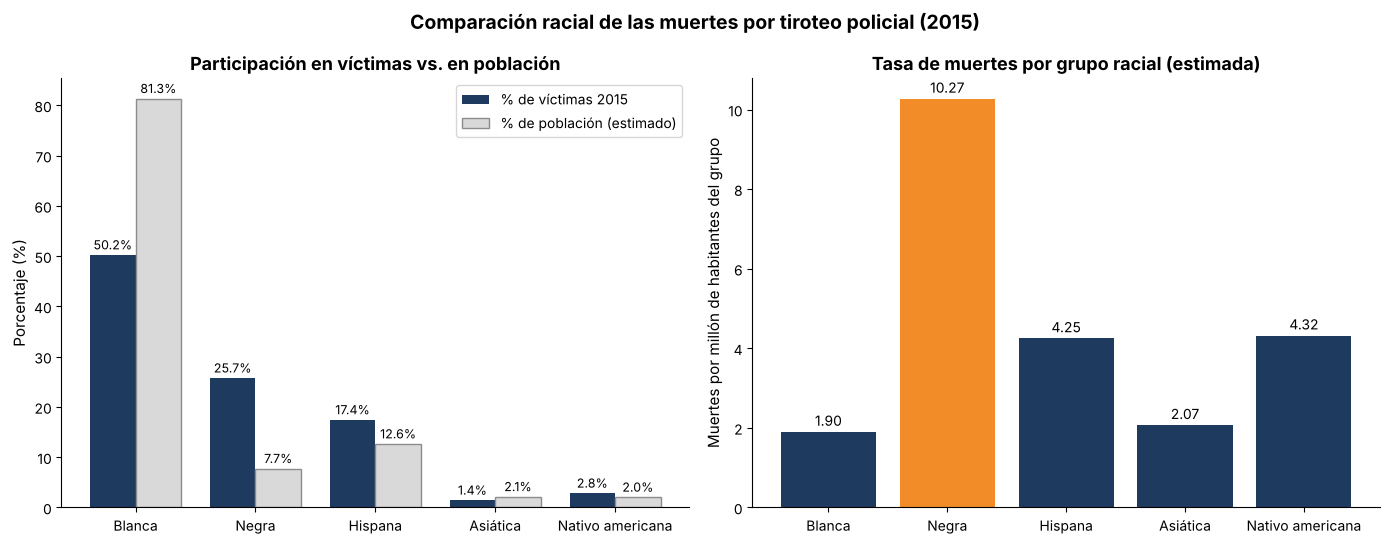

In [34]:
nombres_es = {'W': 'Blanca', 'B': 'Negra', 'H': 'Hispana', 'A': 'Asiática', 'NA': 'Nativo americana'}
etiquetas = [nombres_es[c] for c in comparacion.index]
x = np.arange(len(etiquetas))
ancho = 0.38

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Izquierda: % de víctimas vs % de población (barras agrupadas)
b1 = ax1.bar(x - ancho/2, comparacion['pct_victimas'], ancho, color=AZUL, label='% de víctimas 2015')
b2 = ax1.bar(x + ancho/2, comparacion['pct_poblacion'], ancho, color=GRIS_CLARO, edgecolor=GRIS,
             label='% de población (estimado)')
ax1.bar_label(b1, fmt='%.1f%%', padding=2, fontsize=9)
ax1.bar_label(b2, fmt='%.1f%%', padding=2, fontsize=9)
ax1.set_xticks(x)
ax1.set_xticklabels(etiquetas)
ax1.set_ylabel('Porcentaje (%)')
ax1.set_title('Participación en víctimas vs. en población')
ax1.legend()

# Derecha: muertes por millón de habitantes de cada grupo
colores = [NARANJA if c == 'B' else AZUL for c in comparacion.index]
b3 = ax2.bar(etiquetas, comparacion['muertes_por_millon'], color=colores)
ax2.bar_label(b3, fmt='%.2f', padding=2)
ax2.set_ylabel('Muertes por millón de habitantes del grupo')
ax2.set_title('Tasa de muertes por grupo racial (estimada)')

fig.suptitle('Comparación racial de las muertes por tiroteo policial (2015)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Resultado:** las personas blancas son el grupo con más víctimas (**495**, 50.2 % de las 987 víctimas de los 50 estados), pero representan alrededor del **81.3 %** de la población estimada. Las personas negras son **254 víctimas (25.7 %)**, frente a solo **7.7 %** de la población estimada. Al calcular la tasa, la población negra registra **10.27 muertes por millón**, unas **5.4 veces** la tasa de la población blanca (**1.90**). Las poblaciones hispana (4.25) y nativo americana (4.32) también tienen tasas superiores a la blanca; la asiática (2.07) es similar.

**Precaución sobre los códigos de raza:** el archivo `Races.csv` indica que `NA` = *Native American* y `N` = *Not Hispanic*. Se respetó ese diccionario, pero 28 casos de 2015 tienen `NA`, un número alto para ese grupo; podría tratarse de datos faltantes en el archivo original. Por eso la tasa nativo americana debe tomarse con cautela. Las 24 víctimas con `N` (*Not Hispanic*) u `O` (*Unknown*) no se comparan porque no tienen un grupo de población equivalente.

### C. (Opcional – no cuenta para la evaluación) Estados donde la población negra representa en promedio más del 20 %

*Pregunta de la presentación:* En aquellos estados en los que en promedio la población negra tiene un porcentaje de representación mayor al 20 %, ¿hay indicios de mayor número de muertes por tiroteo que en otros estados?

Se usa el promedio del porcentaje de población negra de las ciudades de cada estado (como dice la pregunta: "en promedio") y se comparan las tasas por millón de habitantes.

In [35]:
promedio_negra_estado = razas_ciudad.groupby('Geographic area')['share_black'].mean().round(1)
estados_mas_20 = promedio_negra_estado[promedio_negra_estado > 20].sort_values(ascending=False)
print('Estados con más de 20% de población negra (promedio de ciudades):')
print(estados_mas_20)

Estados con más de 20% de población negra (promedio de ciudades):
Geographic area
DC    50.7
MS    41.8
SC    32.8
LA    30.8
GA    30.6
AL    23.3
NC    20.4
Name: share_black, dtype: float64


In [36]:
tasas['pct_negra'] = tasas['state'].map(promedio_negra_estado)
tasas['grupo'] = 'Resto de estados'
tasas.loc[tasas['pct_negra'] > 20, 'grupo'] = 'Más de 20% población negra'

resumen_grupos = tasas.groupby('grupo').agg(estados=('state', 'count'),
                                            muertes=('muertes', 'sum'),
                                            poblacion=('poblacion_2015', 'sum'),
                                            promedio_muertes_por_estado=('muertes', 'mean'))
resumen_grupos['muertes_por_millon'] = (resumen_grupos['muertes'] / resumen_grupos['poblacion'] * 1_000_000).round(2)
resumen_grupos['promedio_muertes_por_estado'] = resumen_grupos['promedio_muertes_por_estado'].round(1)
resumen_grupos

,estados,muertes,poblacion,promedio_muertes_por_estado,muertes_por_millon
grupo,,,,,
Más de 20% población negra,6,123,37654796,20.5,3.27
Resto de estados,44,864,283070748,19.6,3.05


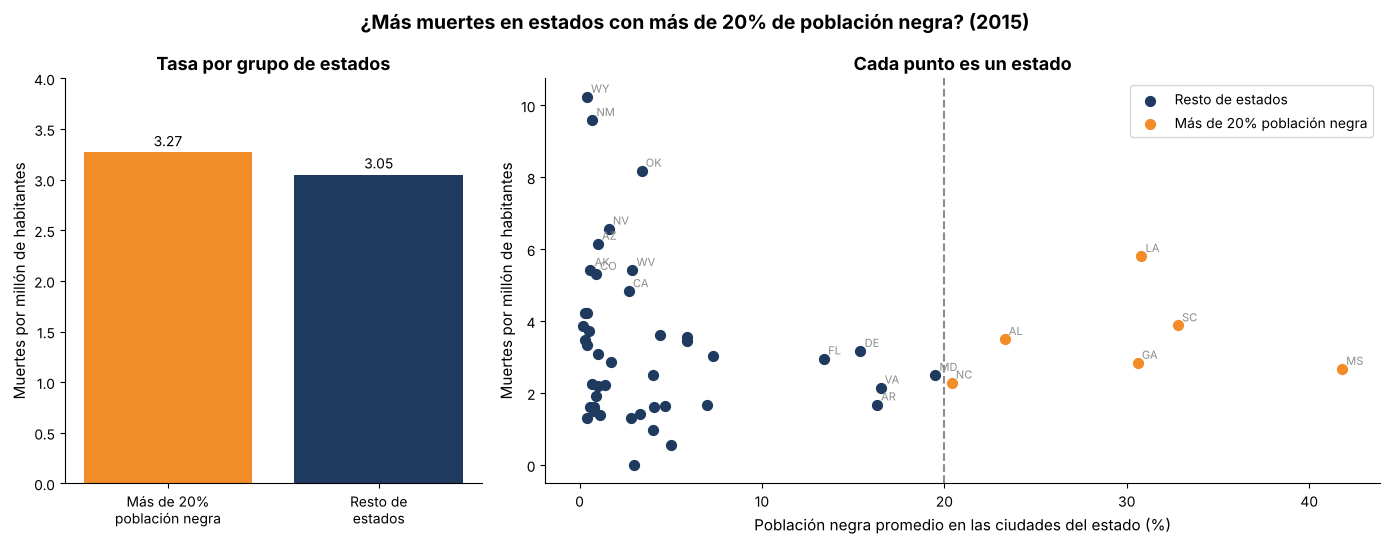

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 2]})

# Izquierda: tasa de cada grupo
b = ax1.bar(['Más de 20%\npoblación negra', 'Resto de\nestados'],
            resumen_grupos.loc[['Más de 20% población negra', 'Resto de estados'], 'muertes_por_millon'],
            color=[NARANJA, AZUL])
ax1.bar_label(b, fmt='%.2f', padding=2)
ax1.set_ylabel('Muertes por millón de habitantes')
ax1.set_title('Tasa por grupo de estados')
ax1.set_ylim(0, 4)

# Derecha: dispersión % población negra vs tasa de cada estado
for grupo, color in [('Resto de estados', AZUL), ('Más de 20% población negra', NARANJA)]:
    sub = tasas[tasas['grupo'] == grupo]
    ax2.scatter(sub['pct_negra'], sub['muertes_por_millon'], color=color, s=50, label=grupo)
# Etiquetamos solo los estados más relevantes para que la gráfica no se sature
for _, fila in tasas.iterrows():
    if fila['pct_negra'] > 10 or fila['muertes_por_millon'] > 4.5:
        ax2.annotate(fila['state'], (fila['pct_negra'], fila['muertes_por_millon']),
                     fontsize=8, color=GRIS, xytext=(3, 3), textcoords='offset points')
ax2.axvline(20, color=GRIS, linestyle='--')
ax2.set_xlabel('Población negra promedio en las ciudades del estado (%)')
ax2.set_ylabel('Muertes por millón de habitantes')
ax2.set_title('Cada punto es un estado')
ax2.legend()

fig.suptitle('¿Más muertes en estados con más de 20% de población negra? (2015)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Resultado (opcional):** los estados con más de 20 % de población negra en promedio son Misisipi, Carolina del Sur, Luisiana, Georgia, Alabama y Carolina del Norte (DC también supera el 20 %, pero no tiene población en el archivo y se excluye). Este grupo tiene **3.27 muertes por millón**, apenas por encima de los otros 44 estados (**3.05**). La dispersión no muestra una tendencia clara: Luisiana tiene una tasa alta (5.81), pero Carolina del Norte (2.29) y Misisipi (2.67) están por debajo del promedio, mientras que los estados con tasas más altas (WY, NM, OK) tienen poca población negra. **No hay indicios claros** de que estos estados tengan más muertes en general; la disparidad racial se ve al comparar **grupos de personas** (sección B), no al comparar estados.

## Conclusiones generales

### ¿California es el estado con mayor probabilidad de sufrir una muerte por tiroteo policial?

**No.** California es el estado con **más muertes** (189 en 2015), más ciudades con tiroteos (114) y aparece en primer lugar en casi todas las preguntas por conteo. Pero eso se explica en gran parte porque es el estado más poblado (39.1 millones de habitantes). Al calcular la tasa, California tiene **4.83 muertes por millón** y ocupa el **lugar 10 de 50**. Los estados con mayor probabilidad relativa son **Wyoming (10.24)**, **Nuevo México (9.59)** y **Oklahoma (8.18)**. Número de muertes y probabilidad de morir no son lo mismo.

### ¿Los resultados proporcionan indicios de un posible sesgo racial?

**Hay indicios de una disparidad racial importante, pero estos datos no prueban por sí solos que la causa sea un sesgo racial.**

* **Disparidad observada:** las personas negras son el 25.7 % de las víctimas pero solo el 7.7 % de la población estimada; su tasa (10.27 por millón) es unas 5.4 veces la de las personas blancas (1.90). En cambio, comparar estados con más de 20 % de población negra contra el resto no muestra una diferencia clara (3.27 vs. 3.05 por millón). Esto es un **indicio** que justifica investigar más.
* **Por qué no es prueba de causalidad:** el análisis no controla otros factores (tasa de contacto con la policía, nivel de amenaza, criminalidad local, pobreza, presencia policial). Tampoco permite saber qué pasó en cada encuentro.
* **Lo que sí vale la pena revisar:** los casos de personas desarmadas (94) o con armas de juguete (43) cruzados por raza, y las ciudades donde la disparidad es mayor.

En resumen: los números muestran que un grupo racial muere en mayor proporción que su peso en la población; eso es una señal de alerta para el panel, no una conclusión definitiva sobre racismo.

### Limitaciones del análisis

* Solo se analizó 2015 (991 muertes); los resultados pueden cambiar en otros años.
* Ingresos y raza vienen **por ciudad** y sin tamaño de ciudad: los promedios son aproximaciones, no cifras oficiales estatales.
* En la pregunta 2 se cruzó el 88.1 % de los casos (126 de 143); hay ciudades registradas como condados o barrios que no coinciden con la tabla de ingresos. 1,913 ciudades no tienen ingreso y `250,000+` se tomó como 250,000.
* `population2015.csv` no incluye DC, por lo que DC no entra en las tasas.
* Algunos grupos tienen muy pocos casos (6 mujeres negras de 25 a 40 años, 6 muertes en Wyoming), por lo que sus resultados son poco estables.
* El significado de los códigos de raza `NA` y `N` se tomó de `Races.csv` del profesor; podrían no coincidir con el dataset original.
* No se usó información externa.